# 01 · Q-Learning

> Implementa Q-Learning (`QLearningAgent.update` en `src/agents.py`), **ajusta sus hiperparámetros** en los cuatro
> mercados, mide el resultado final en test frente a los baselines y analiza si la estrategia aprendida es la
> esperada. Guarda `results/01_qlearning.csv`, con el mismo esquema que `00_baselines.csv`, para el 04.

| § | Contenido | Qué sale de aquí |
|---|---|---|
| 0 | La regla de Q-Learning en una figura | Qué hace cada término |
| 1 | Implementación y prueba | `update()` verificada a mano y coherente con el 00 |
| 2 | Cómo ajustamos los hiperparámetros | Validación aparte del test (D-0.4), por etapas y con 3 semillas |
| 3 | Etapa 1 · tasa de aprendizaje α | α por mercado |
| 4 | Etapa 2 · factor de descuento γ | γ por mercado |
| 5 | Etapa 3 · exploración ε | Decaimiento y ε mínimo por mercado |
| 6 | Etapa 4 · número de episodios y convergencia | Episodios por mercado y velocidad de convergencia |
| 7 | Resultado final en test | `results/01_qlearning.csv` |
| 8 | ¿Es la estrategia esperada? | Política aprendida y un episodio por mercado |
| 9 | El reto del mercado 4 | Por qué no sigue la tendencia |
| 10 | Conclusiones | Decisiones y qué pasa al 04 |

Teoría: [`docs/teoria/02_td_sarsa_qlearning.md`](../docs/teoria/02_td_sarsa_qlearning.md). Punto de partida y
decisiones comunes: [`00_entorno_y_baselines.ipynb`](00_entorno_y_baselines.ipynb).

In [1]:
import os, sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

from src.env import SimpleTradingEnv, discretize, n_states
from src.markets import MARKETS, make_prices
from src.agents import QLearningAgent, BuyHoldAgent, RandomAgent
from src.experiment import (train, evaluate, run_episode, summarize, save_results, quantile_edges, run_grid,
                            run_config, config_id, RESULTS_DIR, N_BINS, N_TEST, N_VAL, RESULT_COLUMNS)
from src.style import setup, savefig, AGENT_COLORS, MARKET_COLORS, MARKET_LABELS

setup()
pd.set_option("display.precision", 3)

QUICK = os.environ.get("NB_QUICK") == "1"     # prueba rápida del notebook: pocos episodios y una semilla
RECALCULAR = False                             # True = ignorar la caché de results/ y reentrenar todo
SEEDS = [0] if QUICK else [0, 1, 2]            # semillas de entrenamiento para el ajuste
SEEDS_FINAL = [0, 1] if QUICK else [0, 1, 2, 3, 4]
N_EP = 40 if QUICK else 500                    # episodios por defecto durante el ajuste
SUF = "_quick" if QUICK else ""
BASE = dict(agente="qlearning", n_bins=N_BINS, alpha=0.001, gamma=0.9, epsilon_decay=0.99,
            epsilon_min=0.01, n_episodes=N_EP, split="val")
baselines = pd.read_csv(RESULTS_DIR / "00_baselines.csv")
print(f"{N_BINS} bins por cuantiles · ajuste en {N_VAL} series de validación · test final en {N_TEST} series"
      f" · semillas de ajuste {SEEDS}" + ("  [MODO RÁPIDO]" if QUICK else ""))

10 bins por cuantiles · ajuste en 100 series de validación · test final en 200 series · semillas de ajuste [0, 1, 2]


## 0. La regla de Q-Learning en una figura

Q-Learning mantiene una tabla $Q(s, a)$: cuánto espera ganar el agente si en el estado $s$ hace $a$ y después
juega lo mejor posible. Tras cada paso corrige la casilla que acaba de usar (slides3 p33):

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\,\big[\,\underbrace{R_{t+1} + \gamma \max_a Q(S_{t+1},a)}_{\text{objetivo TD}} - Q(S_t,A_t)\,\big]$$

El objetivo usa **la mejor acción del estado siguiente** aunque el agente explore con ε-greedy. Por eso es
*off-policy*: aprende la política óptima mientras se comporta de otra forma.

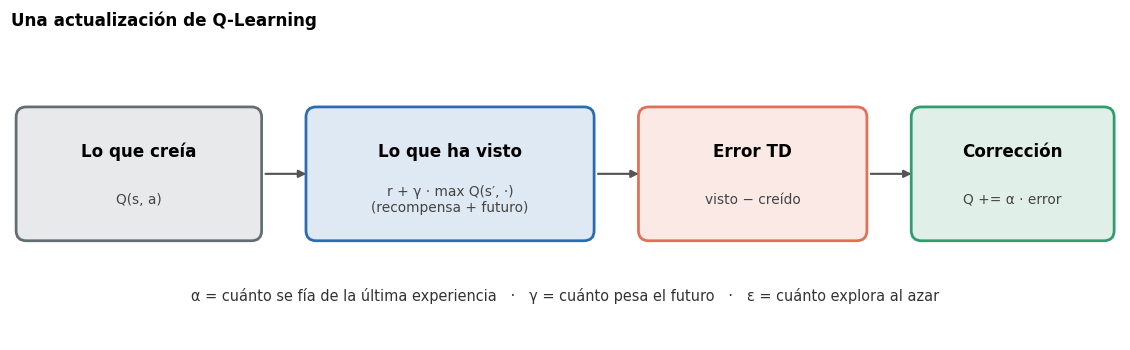

In [2]:
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.set_xlim(0, 13); ax.set_ylim(0, 3.6); ax.axis("off")
def box(x, w, title, sub, color, y=1.2, h=1.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=color, alpha=0.15, ec="none"))
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc="none", ec=color, lw=1.8))
    ax.text(x + w / 2, y + h * 0.68, title, ha="center", va="center", fontsize=11, weight="bold")
    ax.text(x + w / 2, y + h * 0.3, sub, ha="center", va="center", fontsize=9, color="#444")
box(0.1, 2.8, "Lo que creía", "Q(s, a)", "#636E72")
box(3.5, 3.3, "Lo que ha visto", "r + γ · max Q(s′, ·)\n(recompensa + futuro)", AGENT_COLORS["qlearning"])
box(7.4, 2.6, "Error TD", "visto − creído", "#E17055")
box(10.6, 2.3, "Corrección", "Q += α · error", "#2F9E6E")
for x1, x2 in [(2.95, 3.5), (6.85, 7.4), (10.05, 10.6)]:
    ax.annotate("", (x2, 1.95), (x1, 1.95), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.4))
ax.text(6.5, 0.45, "α = cuánto se fía de la última experiencia   ·   γ = cuánto pesa el futuro   ·   "
        "ε = cuánto explora al azar", ha="center", fontsize=9.5, color="#333")
ax.set_title("Una actualización de Q-Learning", loc="left")
savefig(fig, "01_regla_qlearning"); plt.show()

## 1. Implementación y prueba

La regla está en `src/agents.py`, con $Q(\text{terminal}, \cdot) = 0$:

```python
def update(self, s, a, r, s2, a2, done):
    target = r if done else r + self.gamma * self.Q[s2].max()
    self.Q[s, a] += self.alpha * (target - self.Q[s, a])
```

`run_episode` (en `src/experiment.py`) actualiza **antes** de elegir la siguiente acción, como en el pseudocódigo
de slides3 p36 (D-2.1). Dos comprobaciones: un paso calculado a mano y que el agente oficial reproduce el
Q-Learning de calibración del 00. La segunda usa el test **solo para comparar con la cifra que ya publicó el 00**; no
interviene en ninguna elección de hiperparámetros.

In [3]:
ag = QLearningAgent(alpha=0.5, gamma=0.9)
ag.Q[3] = [0.0, 0.2, 0.1]                                  # Q del estado siguiente: la mejor acción vale 0,2
ag.update(s=0, a=2, r=0.01, s2=3, a2=None, done=False)
esperado = 0.5 * (0.01 + 0.9 * 0.2 - 0)
display(pd.DataFrame({"Q(0, comprar)": [ag.Q[0, 2]], "a mano: 0,5·(0,01 + 0,9·0,2 − 0)": [esperado],
                      "coinciden": [np.isclose(ag.Q[0, 2], esperado)]}).style.hide(axis="index"))

ag.update(s=1, a=0, r=-0.001, s2=3, a2=None, done=True)   # paso final: no hay futuro
print(f"Paso terminal: Q(1, vender) = {ag.Q[1, 0]:+.5f} (= 0,5 · −0,001, sin término de futuro)")

if not QUICK:
    fila, _, _ = run_config({**BASE, "mercado": "reversion_media", "seed": 0, "split": "test"})
    print(f"Reversión a la media, α = 0,001, γ = 0,9, 500 episodios: mediana en test {fila['retorno_mediana']:+.1%}"
          f" (en el 00, §7.2: +13,6 %) → coherente con el 00")

"Q(0, comprar)","a mano: 0,5·(0,01 + 0,9·0,2 − 0)",coinciden
0.095000,0.095000,True


Paso terminal: Q(1, vender) = -0.00050 (= 0,5 · −0,001, sin término de futuro)


Reversión a la media, α = 0,001, γ = 0,9, 500 episodios: mediana en test +13.6% (en el 00, §7.2: +13,6 %) → coherente con el 00


## 2. Cómo ajustamos los hiperparámetros

**Regla de oro: el test no se mira hasta el final.** Si eligiéramos α, γ o ε mirando las series de test, el
resultado final saldría optimista. Para elegir se usan **100 series de validación** (semillas desde 50 000), distintas
de las de entrenamiento y de las de test (**D-0.4**).

El ajuste va **por etapas**: cada etapa barre un hiperparámetro dejando fijos los ya elegidos. Cada configuración se
entrena con **3 semillas** (exploración distinta y series de entrenamiento distintas) y se puntúa con la **mediana
entre semillas** de la mediana del retorno en validación. Así una semilla con suerte no decide sola.

Se elige **por mercado**: los cuatro son muy distintos y nada obliga a usar los mismos hiperparámetros.

**Regla de parsimonia (para no perseguir ruido):** un valor nuevo solo sustituye al de partida si **le gana en la
mayoría de las semillas**, comparando cada semilla con la misma semilla del valor de partida (mismas series de
entrenamiento), y además tiene mejor mediana. Así, una mejora de +3 % que sale de una sola operación afortunada no
cambia la configuración. Si nada convence, se mantiene el valor de partida.

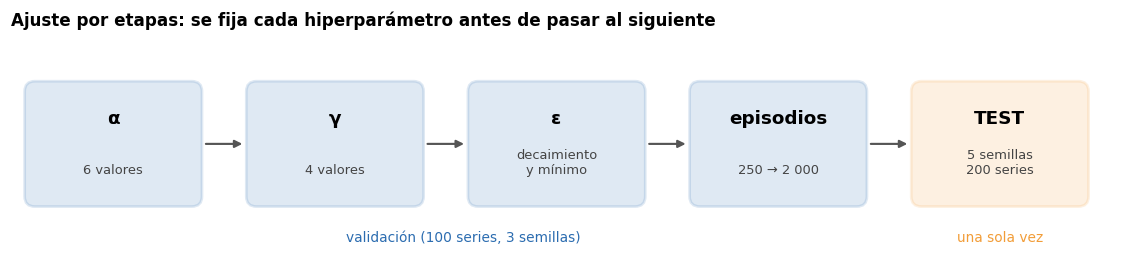

In [4]:
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.set_xlim(0, 13); ax.set_ylim(0, 2.6); ax.axis("off")
etapas = [("α", "6 valores"), ("γ", "4 valores"), ("ε", "decaimiento\ny mínimo"), ("episodios", "250 → 2 000"),
          ("TEST", "5 semillas\n200 series")]
for i, (t, s) in enumerate(etapas):
    x = 0.2 + i * 2.6; c = "#F29D38" if t == "TEST" else AGENT_COLORS["qlearning"]
    ax.add_patch(FancyBboxPatch((x, 0.6), 2.0, 1.4, boxstyle="round,pad=0.04,rounding_size=0.12", fc=c, alpha=0.15, ec=c, lw=1.8))
    ax.text(x + 1.0, 1.55, t, ha="center", fontsize=12, weight="bold"); ax.text(x + 1.0, 0.95, s, ha="center", fontsize=8.5, color="#444")
    if i < len(etapas) - 1:
        ax.annotate("", (x + 2.55, 1.3), (x + 2.05, 1.3), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.4))
ax.text(5.3, 0.15, "validación (100 series, 3 semillas)", ha="center", fontsize=9, color=AGENT_COLORS["qlearning"])
ax.text(10.6 + 1.0, 0.15, "una sola vez", ha="center", fontsize=9, color="#F29D38")
ax.set_title("Ajuste por etapas: se fija cada hiperparámetro antes de pasar al siguiente", loc="left")
savefig(fig, "01_etapas_ajuste"); plt.show()

In [5]:
def grid(param_values, base_por_mercado, nombre):
    """Barre los valores de `param_values` ({param: [valores]}) sobre la config de cada mercado, con SEEDS."""
    cfgs = []
    for m in MARKETS:
        for combo in pd.MultiIndex.from_product(list(param_values.values()), names=list(param_values)):
            combo = combo if isinstance(combo, tuple) else (combo,)
            for s in SEEDS:
                cfgs.append({**base_por_mercado[m], **dict(zip(param_values, combo)), "mercado": m, "seed": s})
    df, curvas, qs = run_grid(cfgs, nombre + SUF, recompute=RECALCULAR)
    return df, curvas, qs

def puntuar(df, params):
    """Mediana entre semillas de la mediana en validación, y operaciones medias."""
    return df.groupby(["mercado"] + params).agg(score=("retorno_mediana", "median"),
                                               ops=("n_trades", "mean")).reset_index()

def elegir(df, sc, params, base_por_mercado):
    """Mejor valor por mercado con regla de parsimonia: un valor solo sustituye al de partida si le gana
    en la mayoría de las semillas (comparación semilla a semilla) y tiene mejor mediana entre semillas."""
    nuevo = {}
    for m in MARKETS:
        base_vals = tuple(base_por_mercado[m][p] for p in params)
        d = df[df.mercado == m].copy(); d["combo"] = d[params].apply(tuple, axis=1)
        base_por_semilla = d[d.combo == base_vals].set_index("seed").retorno_mediana
        sub = sc[sc.mercado == m].copy(); sub["combo"] = sub[params].apply(tuple, axis=1)
        def gana(combo):
            cand = d[d.combo == combo].set_index("seed").retorno_mediana
            return (cand > base_por_semilla + 1e-9).sum() > len(SEEDS) / 2
        sub["elegible"] = [(c == base_vals) or gana(c) for c in sub.combo]
        fila = sub[sub.elegible].sort_values("score", ascending=False).iloc[0]
        nuevo[m] = {**base_por_mercado[m], **{p: fila[p] for p in params}}
    return nuevo

def fmt_ret(v, m):
    return f"x{1 + v:,.0f}" if m == "tendencia_ciclo" else f"{v:+.1%}"

def heatmap(sc, param, titulo, nombre_fig, etiquetas=None, elegido=None):
    """Mapa mercado × valor: color por posición dentro de cada mercado (verde = mejor), texto = mediana y ops."""
    vals = sorted(sc[param].unique())
    fig, ax = plt.subplots(figsize=(1.6 + 1.55 * len(vals), 3.6))
    for i, m in enumerate(MARKETS):
        sub = sc[sc.mercado == m].set_index(param).loc[vals]
        rng = sub.score.max() - sub.score.min()
        rel = (sub.score - sub.score.min()) / rng if rng > 1e-12 else pd.Series(0.5, index=sub.index)
        for j, v in enumerate(vals):
            ax.add_patch(plt.Rectangle((j, 3 - i), 1, 1, fc=plt.cm.RdYlGn(0.15 + 0.7 * rel.loc[v]), ec="white", lw=2))
            ops = sub.loc[v, "ops"]
            txt = fmt_ret(sub.loc[v, "score"], m) + ("\nno opera" if ops < 0.5 else f"\n{ops:.0f} ops")
            ax.text(j + 0.5, 3.5 - i, txt, ha="center", va="center", fontsize=8.5, weight="bold", color="#222")
            sel = None if elegido is None else elegido[m][param]
            if sel is not None and ((sel == v) if isinstance(v, str) else np.isclose(sel, v)):
                ax.add_patch(plt.Rectangle((j + 0.04, 3.04 - i), 0.92, 0.92, fc="none", ec="black", lw=2.2))
    ax.set_xlim(0, len(vals)); ax.set_ylim(0, 4); ax.grid(False)
    ax.set_xticks(np.arange(len(vals)) + 0.5, etiquetas or [str(v) for v in vals])
    ax.set_yticks(np.arange(4) + 0.5, [MARKET_LABELS[m] for m in reversed(list(MARKETS))])
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.tick_params(length=0); ax.set_title(titulo, loc="left")
    fig.tight_layout(); savefig(fig, nombre_fig); plt.show()

def tabla_elegidos(cfg_m, params):
    return pd.DataFrame({MARKET_LABELS[m]: {p: cfg_m[m][p] for p in params} for m in MARKETS}).T

## 3. Etapa 1 · Tasa de aprendizaje α

El 00 ya avisó de que α es crítico (D-2.2): con α grande, el ruido de Q tapa la señal. Ahora se barre con más
detalle, con 3 semillas y en validación. Cada casilla muestra la mediana en validación y las operaciones por
episodio. El recuadro negro marca el valor elegido para cada mercado, y el color compara solo dentro de cada fila.

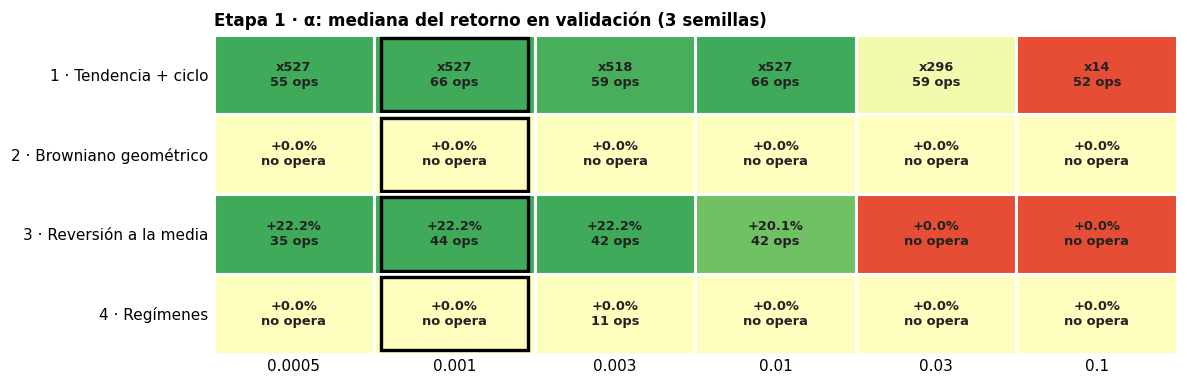

,alpha
1 · Tendencia + ciclo,0.001000
2 · Browniano geométrico,0.001000
3 · Reversión a la media,0.001000
4 · Regímenes,0.001000


In [6]:
ALPHAS = [0.0005, 0.001, 0.003, 0.01, 0.03, 0.1]
base0 = {m: dict(BASE) for m in MARKETS}
df_a, _, _ = grid({"alpha": ALPHAS}, base0, "01_grid_alpha")
sc_a = puntuar(df_a, ["alpha"])
cfg1 = elegir(df_a, sc_a, ["alpha"], base0)
heatmap(sc_a, "alpha", "Etapa 1 · α: mediana del retorno en validación (3 semillas)", "01_ajuste_alpha", elegido=cfg1)
display(tabla_elegidos(cfg1, ["alpha"]).style.set_caption("α elegido por mercado"))

## 4. Etapa 2 · Factor de descuento γ

γ decide cuánto pesa el futuro. Con **γ = 0** el agente solo mira la recompensa del paso siguiente (un "miope" que
compra si espera que el precio suba ya). Con γ cercano a 1 tiene en cuenta todo lo que viene, incluidas las
comisiones de salir más tarde. Con regímenes de unos 50 pasos o ciclos de unos 63, cabe esperar que mirar lejos ayude.

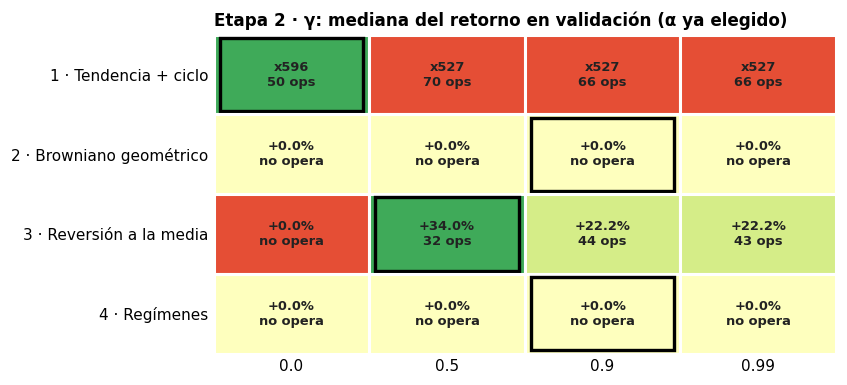

,alpha,gamma
1 · Tendencia + ciclo,0.001000,0.000000
2 · Browniano geométrico,0.001000,0.900000
3 · Reversión a la media,0.001000,0.500000
4 · Regímenes,0.001000,0.900000


In [7]:
GAMMAS = [0.0, 0.5, 0.9, 0.99]
df_g, _, _ = grid({"gamma": GAMMAS}, cfg1, "01_grid_gamma")
sc_g = puntuar(df_g, ["gamma"])
cfg2 = elegir(df_g, sc_g, ["gamma"], cfg1)
heatmap(sc_g, "gamma", "Etapa 2 · γ: mediana del retorno en validación (α ya elegido)", "01_ajuste_gamma", elegido=cfg2)
display(tabla_elegidos(cfg2, ["alpha", "gamma"]).style.set_caption("α y γ elegidos por mercado"))

**La hipótesis solo se cumple a medias.** En el mercado 3 mirar algo al futuro ayuda: con γ = 0 no opera, y el mejor
es γ = 0,5, porque el rebote tarda varios pasos en llegar. En el mercado 1, en cambio, gana **γ = 0, el agente
miope**. Una explicación coherente con los datos es que ese mercado tiene un ruido de σ ≈ 10 % por paso (00 §2, la
figura de los mercados), así que el valor de los pasos lejanos se estima con muchísimo ruido. Su ciclo está en los
retornos y los hace persistentes, de modo que la tendencia actual ya predice bien el retorno del paso siguiente. En
los mercados 2 y 4 γ no importa, porque el agente no opera con ningún valor.

## 5. Etapa 3 · Exploración ε

ε empieza en 1 (todo al azar) y se multiplica por `epsilon_decay` tras cada episodio, hasta `epsilon_min`. El
profesor recomendó **que decaiga** y **no llevarlo a 0 si el mercado cambia** (transcripción ~01:10 y ~01:21), así
que se prueba también un mínimo de 0,05. Arriba, cómo baja ε con cada ritmo.

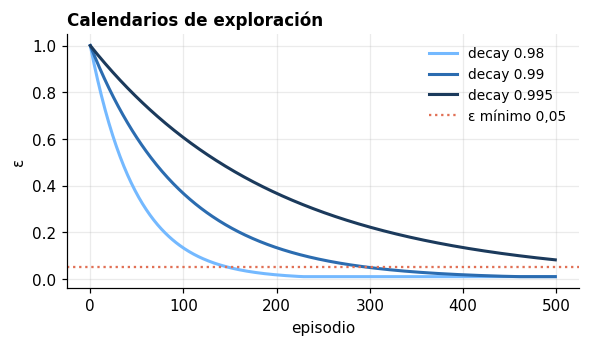

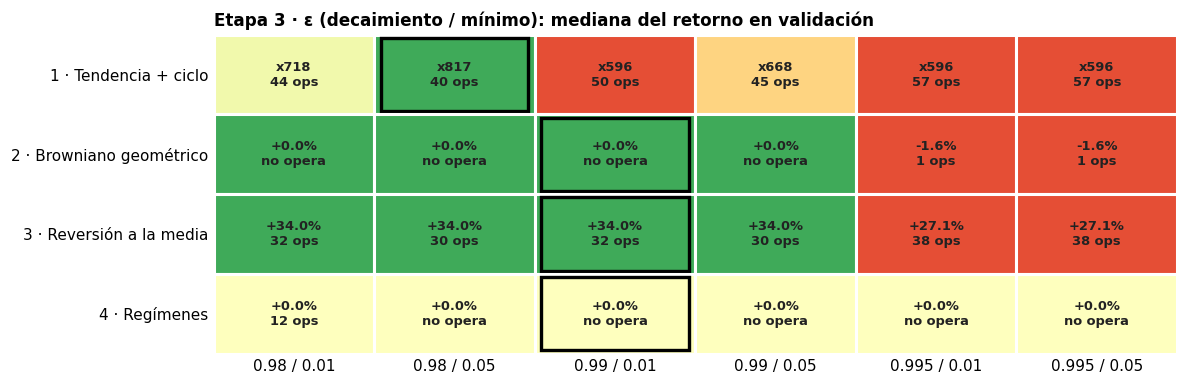

,alpha,gamma,epsilon_decay,epsilon_min
1 · Tendencia + ciclo,0.001000,0.000000,0.980000,0.050000
2 · Browniano geométrico,0.001000,0.900000,0.990000,0.010000
3 · Reversión a la media,0.001000,0.500000,0.990000,0.010000
4 · Regímenes,0.001000,0.900000,0.990000,0.010000


In [8]:
DECAYS, EPS_MIN = [0.98, 0.99, 0.995], [0.01, 0.05]
fig, ax = plt.subplots(figsize=(6, 3))
ep = np.arange(N_EP)
for d, c in zip(DECAYS, ["#74B9FF", AGENT_COLORS["qlearning"], "#1B3A5C"]):
    ax.plot(ep, np.maximum(0.01, d ** ep), color=c, lw=2, label=f"decay {d}")
ax.axhline(0.05, color="#E17055", ls=":", lw=1.5, label="ε mínimo 0,05")
ax.set_xlabel("episodio"); ax.set_ylabel("ε"); ax.set_title("Calendarios de exploración", loc="left"); ax.legend()
savefig(fig, "01_calendarios_epsilon"); plt.show()

df_e, _, _ = grid({"epsilon_decay": DECAYS, "epsilon_min": EPS_MIN}, cfg2, "01_grid_epsilon")
sc_e = puntuar(df_e, ["epsilon_decay", "epsilon_min"])
cfg3 = elegir(df_e, sc_e, ["epsilon_decay", "epsilon_min"], cfg2)
sc_e["ε"] = sc_e.epsilon_decay.astype(str) + " / " + sc_e.epsilon_min.astype(str)
for m in MARKETS:
    cfg3[m]["ε"] = f"{cfg3[m]['epsilon_decay']} / {cfg3[m]['epsilon_min']}"
heatmap(sc_e, "ε", "Etapa 3 · ε (decaimiento / mínimo): mediana del retorno en validación", "01_ajuste_epsilon", elegido=cfg3)
for m in MARKETS:
    cfg3[m].pop("ε")
display(tabla_elegidos(cfg3, ["alpha", "gamma", "epsilon_decay", "epsilon_min"]).style.set_caption("Elegidos tras la etapa 3"))

## 6. Etapa 4 · Número de episodios y convergencia

Más episodios significa más experiencia, pero también más tiempo. Se entrena con 250, 500, 1 000 y 2 000 episodios
y se mide en validación. Las curvas de aprendizaje de 2 000 episodios muestran **cuándo converge** cada mercado: el
punto marca el episodio en que la media móvil alcanza el 90 % de su mejora total (`convergence_episode`, D-0.3).

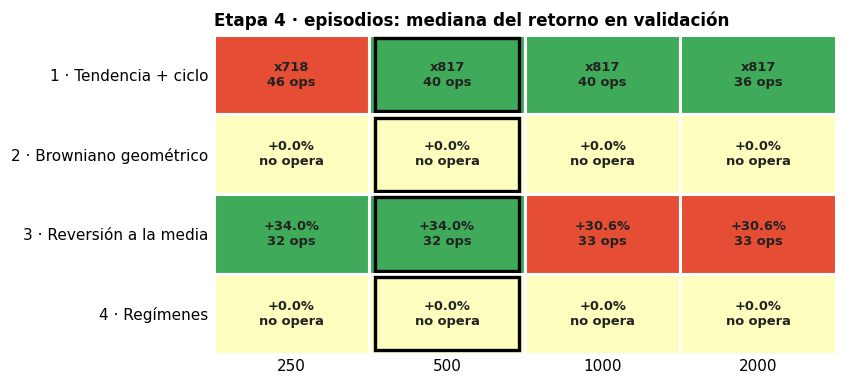

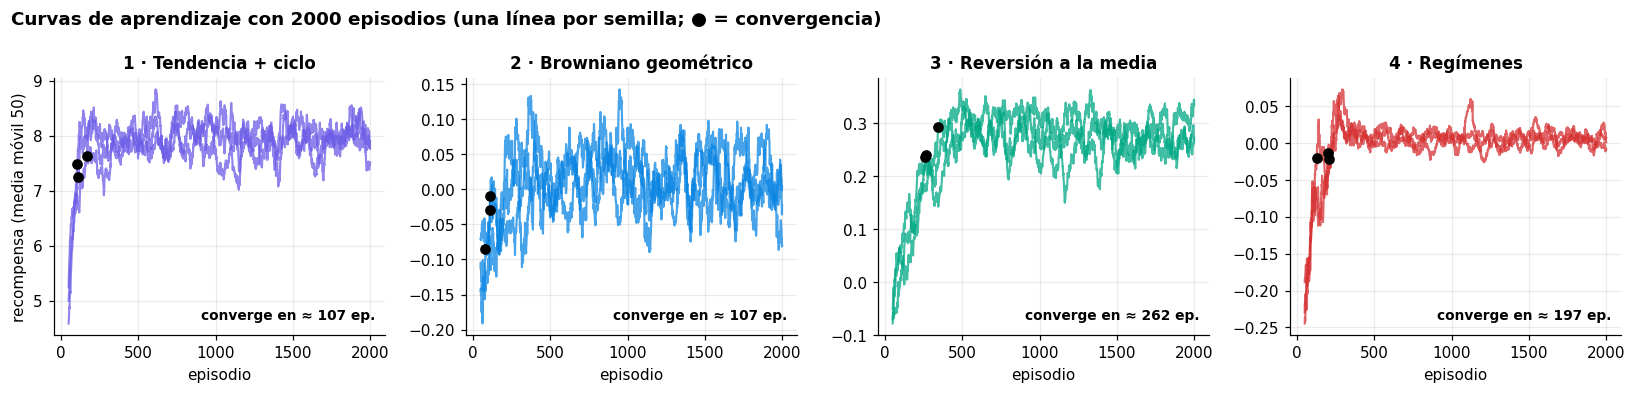

,"episodio de convergencia (mediana de 3 semillas, 2000 ep.)"
1 · Tendencia + ciclo,107
2 · Browniano geométrico,— (no opera)
3 · Reversión a la media,262
4 · Regímenes,— (no opera)


,alpha,gamma,epsilon_decay,epsilon_min,n_episodes
1 · Tendencia + ciclo,0.001000,0.000000,0.980000,0.050000,500.000000
2 · Browniano geométrico,0.001000,0.900000,0.990000,0.010000,500.000000
3 · Reversión a la media,0.001000,0.500000,0.990000,0.010000,500.000000
4 · Regímenes,0.001000,0.900000,0.990000,0.010000,500.000000


In [9]:
EPISODIOS = [20, 40] if QUICK else [250, 500, 1000, 2000]
df_n, curvas_n, _ = grid({"n_episodes": EPISODIOS}, cfg3, "01_grid_episodios")
sc_n = puntuar(df_n, ["n_episodes"])
cfg4 = elegir(df_n, sc_n, ["n_episodes"], cfg3)
heatmap(sc_n, "n_episodes", "Etapa 4 · episodios: mediana del retorno en validación", "01_ajuste_episodios", elegido=cfg4)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
largo = max(EPISODIOS)
for ax, m in zip(axes, MARKETS):
    sub = df_n[(df_n.mercado == m) & (df_n.n_episodes == largo)]
    for _, r in sub.iterrows():
        curva = pd.Series(curvas_n[r["id"]]).rolling(min(50, largo // 2)).mean()
        ax.plot(curva, color=MARKET_COLORS[m], alpha=0.75, lw=1.4)
        ce = min(int(r["episodios_convergencia"]), len(curva) - 1)
        ax.plot(ce, curva.iloc[ce], "o", color="black", ms=6, zorder=5)
    ax.set_title(MARKET_LABELS[m]); ax.set_xlabel("episodio")
    ax.text(0.97, 0.06, f"converge en ≈ {sub.episodios_convergencia.median():.0f} ep.", transform=ax.transAxes,
            ha="right", fontsize=9, weight="bold")
axes[0].set_ylabel("recompensa (media móvil 50)")
fig.suptitle(f"Curvas de aprendizaje con {largo} episodios (una línea por semilla; ● = convergencia)", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "01_curvas_convergencia"); plt.show()
conv = (df_n[df_n.n_episodes == largo].groupby("mercado")
        .agg(convergencia=("episodios_convergencia", "median"), ops=("n_trades", "mean")).reindex(list(MARKETS)))
conv["convergencia"] = [f"{c:.0f}" if o >= 0.5 else "— (no opera)" for c, o in zip(conv.convergencia, conv.ops)]
conv.index = [MARKET_LABELS[m] for m in conv.index]
display(conv[["convergencia"]].rename(columns={"convergencia": f"episodio de convergencia (mediana de {len(SEEDS)} semillas, {largo} ep.)"})
        .style.set_caption("Velocidad de convergencia"))
display(tabla_elegidos(cfg4, ["alpha", "gamma", "epsilon_decay", "epsilon_min", "n_episodes"])
        .style.set_caption("Hiperparámetros finales de Q-Learning por mercado"))

**Cómo leer la convergencia.** En los mercados 2 y 4 el agente acaba sin operar, así que su curva sube solo porque ε
baja y deja de hacer operaciones aleatorias que pagan comisión. Eso no es aprender una estrategia, y por eso no se le
asigna episodio de convergencia.

**Limitación:** el número de episodios y el calendario de ε están acoplados. Con un decaimiento de 0,99, a los 250
episodios ε todavía vale ≈ 0,08 y a los 500 ya está en el mínimo. "500 bastan" quiere decir "500 con este
calendario"; con un decaimiento más lento harían falta más.

## 7. Resultado final en test

Ahora sí, **una sola vez**: cada mercado se entrena con sus hiperparámetros con **5 semillas** y se evalúa en las 200
series de test, las mismas que los baselines del 00. La fila de `results/01_qlearning.csv` de cada mercado es la
mediana de las 5 semillas, y el detalle por semilla queda en `results/01_qlearning_semillas.csv`.

In [10]:
cfgs_final = [{**cfg4[m], "mercado": m, "seed": s, "split": "test"} for m in MARKETS for s in SEEDS_FINAL]
df_f, curvas_f, qs_f = run_grid(cfgs_final, "01_qlearning_semillas" + SUF, recompute=RECALCULAR)

num = ["retorno_mediana", "retorno_medio", "std", "sharpe", "max_drawdown", "n_trades", "episodios_convergencia", "tiempo_s"]
final = df_f.groupby("mercado")[num].median().reindex(list(MARKETS)).reset_index().assign(agente="qlearning")
if not QUICK:
    save_results(final.to_dict("records"), "01_qlearning")

comp = pd.concat([baselines, final[RESULT_COLUMNS]])
tabla = comp.pivot(index="mercado", columns="agente", values="retorno_mediana").reindex(list(MARKETS))[["aleatorio", "buy_hold", "qlearning"]]
rango = df_f.groupby("mercado").retorno_mediana.agg(["min", "max"]).reindex(list(MARKETS))
tabla["semillas (mín – máx)"] = [f"{fmt_ret(a, m)} – {fmt_ret(b, m)}" for m, a, b in zip(rango.index, rango["min"], rango["max"])]
tabla["¿bate a B&H?"] = np.where(tabla.qlearning > tabla.buy_hold + 1e-9, "sí", "no")
tabla["ops/episodio"] = final.set_index("mercado").n_trades.round(0)
tabla.index = [MARKET_LABELS[m] for m in tabla.index]
display(tabla.style.format({c: "{:+.1%}" for c in ["aleatorio", "buy_hold", "qlearning"]})
        .map(lambda v: "color:#2F9E6E;font-weight:bold" if v == "sí" else "color:#D63031", subset=["¿bate a B&H?"])
        .set_caption(f"Mediana del retorno en test ({N_TEST} series) · Q-Learning: mediana de {len(SEEDS_FINAL)} semillas"))

riesgo = comp[comp.agente.isin(["buy_hold", "qlearning"])].pivot(index="mercado", columns="agente",
                                                                 values=["sharpe", "max_drawdown"]).reindex(list(MARKETS))
riesgo.columns = [f"{'Sharpe' if a == 'sharpe' else 'drawdown máx.'} · {'B&H' if c == 'buy_hold' else 'Q-Learning'}" for a, c in riesgo.columns]
riesgo.index = [MARKET_LABELS[m] for m in riesgo.index]
display(riesgo.style.format({c: ("{:.1%}" if "drawdown" in c else "{:+.3f}") for c in riesgo.columns})
        .set_caption("Riesgo en test: Sharpe por paso y caída máxima media (Q-Learning: mediana de semillas)"))

agente,aleatorio,buy_hold,qlearning,semillas (mín – máx),¿bate a B&H?,ops/episodio
1 · Tendencia + ciclo,+330.4%,+3261.7%,+50130.0%,x472 – x605,sí,48.000000
2 · Browniano geométrico,-19.4%,-3.5%,+0.0%,+0.0% – +0.0%,sí,0.000000
3 · Reversión a la media,-17.2%,-0.3%,+27.0%,+22.5% – +27.0%,sí,29.000000
4 · Regímenes,-22.0%,-12.5%,+0.0%,+0.0% – +0.0%,sí,0.000000


,Sharpe · B&H,Sharpe · Q-Learning,drawdown máx. · B&H,drawdown máx. · Q-Learning
1 · Tendencia + ciclo,+0.115,+0.193,89.5%,64.3%
2 · Browniano geométrico,+0.001,+0.000,41.3%,0.0%
3 · Reversión a la media,+0.010,+0.041,25.9%,19.6%
4 · Regímenes,-0.011,+0.000,45.0%,0.0%


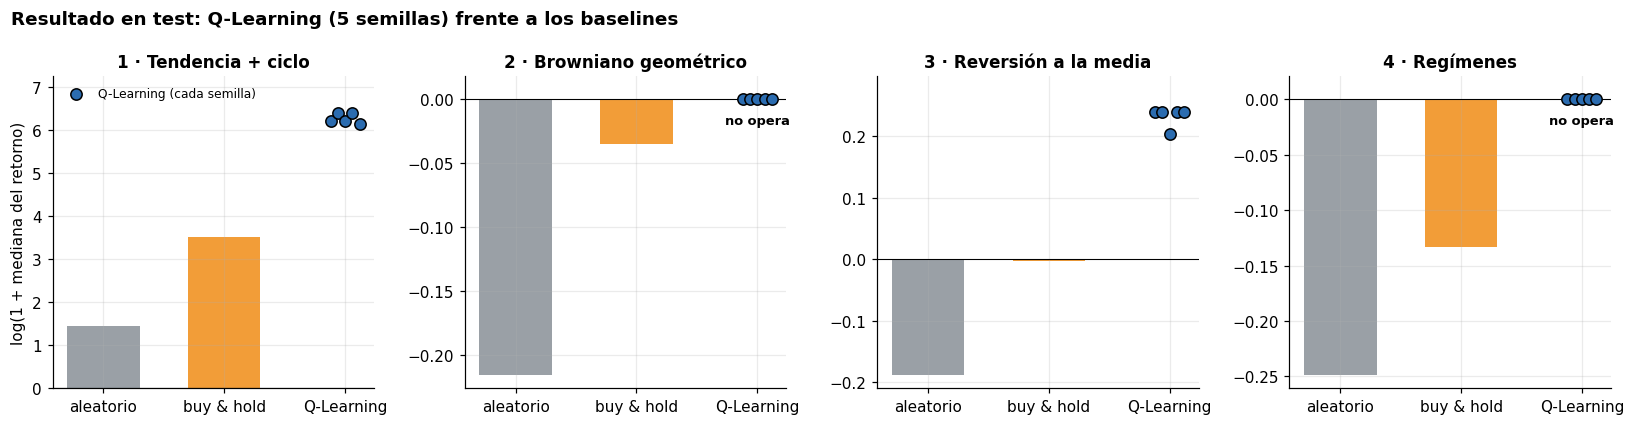

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, m in zip(axes, MARKETS):
    vals = df_f[df_f.mercado == m].retorno_mediana.to_numpy()
    ax.scatter(np.full(len(vals), 2) + np.linspace(-0.12, 0.12, len(vals)), np.log1p(vals), s=55,
               color=AGENT_COLORS["qlearning"], edgecolor="black", zorder=5, label="Q-Learning (cada semilla)")
    for x, a in [(0, "aleatorio"), (1, "buy_hold")]:
        v = baselines[(baselines.mercado == m) & (baselines.agente == a)].retorno_mediana.iloc[0]
        ax.bar(x, np.log1p(v), color=AGENT_COLORS[a], width=0.6)
    ax.axhline(0, color="black", lw=0.7)
    if np.all(np.abs(vals) < 1e-12):
        ax.annotate("no opera", (2, 0), xytext=(0, -16), textcoords="offset points", ha="center", fontsize=8.5, weight="bold")
    lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.08 * (hi - lo))
    ax.set_xticks([0, 1, 2], ["aleatorio", "buy & hold", "Q-Learning"]); ax.set_title(MARKET_LABELS[m])
axes[0].set_ylabel("log(1 + mediana del retorno)"); axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Resultado en test: Q-Learning (5 semillas) frente a los baselines", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "01_resultado_test"); plt.show()

## 8. ¿Es la estrategia esperada?

En el 00 (§2) planteamos qué estrategia cabía esperar en cada mercado. Aquí se compara con lo que ha aprendido el
agente final: primero el **mapa de la política** de cada semilla (entra, se queda fuera, sale o sigue dentro según el
bin de tendencia) y después **un episodio de test** con el agente de la semilla 0.

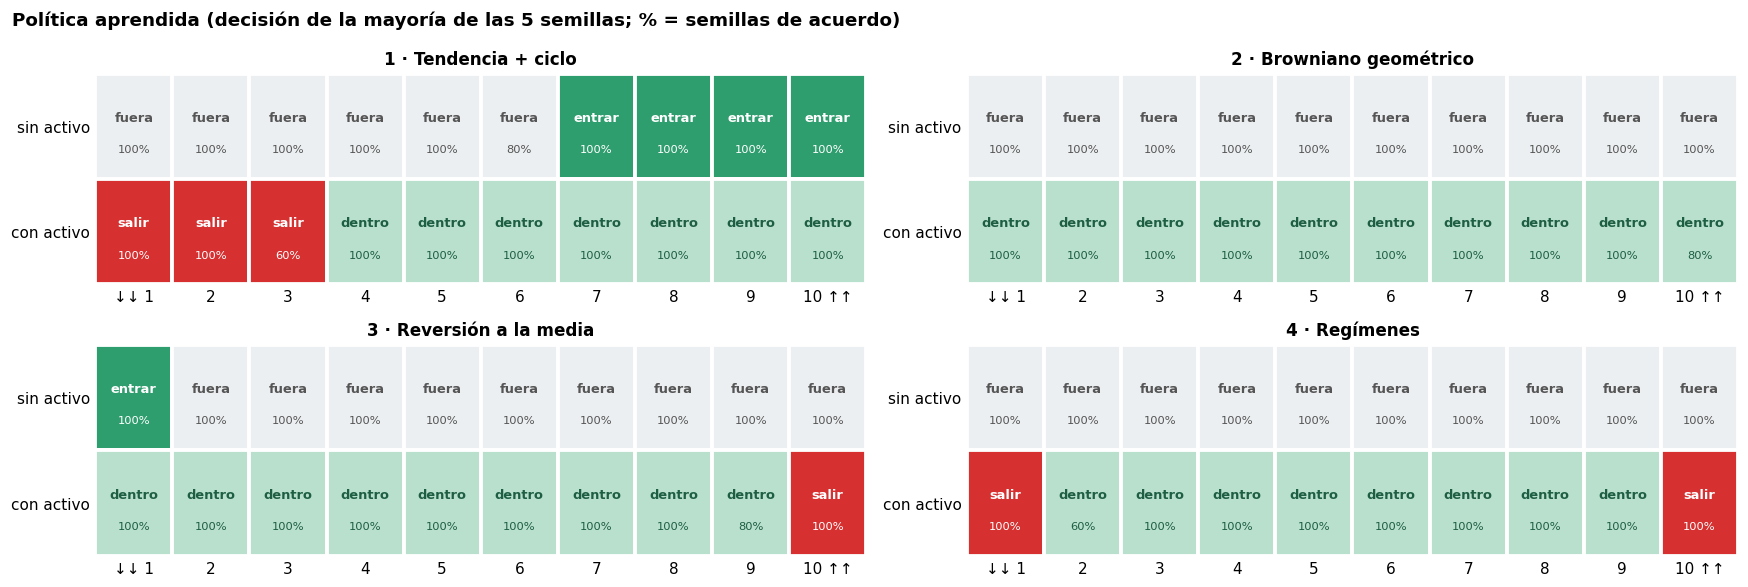

In [12]:
EFECTO = {(0, True): ("entrar", "#2F9E6E", "white"), (0, False): ("fuera", "#ECEFF1", "#555"),
          (1, True): ("salir", "#D63031", "white"), (1, False): ("dentro", "#B8E0CC", "#1E5E43")}
fig, axes = plt.subplots(2, 2, figsize=(16, 5.4))
for ax, m in zip(axes.ravel(), MARKETS):
    ids = df_f[df_f.mercado == m].id.tolist()
    pols = np.array([qs_f[i].reshape(-1, 2, 3).argmax(axis=2) for i in ids])      # [semilla, bin, posición]
    for b in range(pols.shape[1]):
        for pos in (0, 1):
            opera = (pols[:, b, pos] == (2 if pos == 0 else 0))
            mayoria = opera.mean() > 0.5
            txt, fc, tc = EFECTO[(pos, mayoria)]
            ax.add_patch(plt.Rectangle((b, 1 - pos), 1, 1, fc=fc, ec="white", lw=2.5))
            ax.text(b + 0.5, 1.58 - pos, txt, ha="center", va="center", fontsize=8.5, color=tc, weight="bold")
            ax.text(b + 0.5, 1.28 - pos, f"{max(opera.mean(), 1 - opera.mean()):.0%}", ha="center", va="center", fontsize=7.5, color=tc)
    nb_ = pols.shape[1]
    ax.set_xlim(0, nb_); ax.set_ylim(0, 2); ax.grid(False)
    ax.set_xticks(np.arange(nb_) + 0.5, ["↓↓ 1"] + [str(i) for i in range(2, nb_)] + [f"{nb_} ↑↑"])
    ax.set_yticks([0.5, 1.5], ["con activo", "sin activo"]); ax.set_title(MARKET_LABELS[m])
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.tick_params(length=0)
fig.suptitle(f"Política aprendida (decisión de la mayoría de las {len(SEEDS_FINAL)} semillas; % = semillas de acuerdo)",
             x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "01_politica_final"); plt.show()

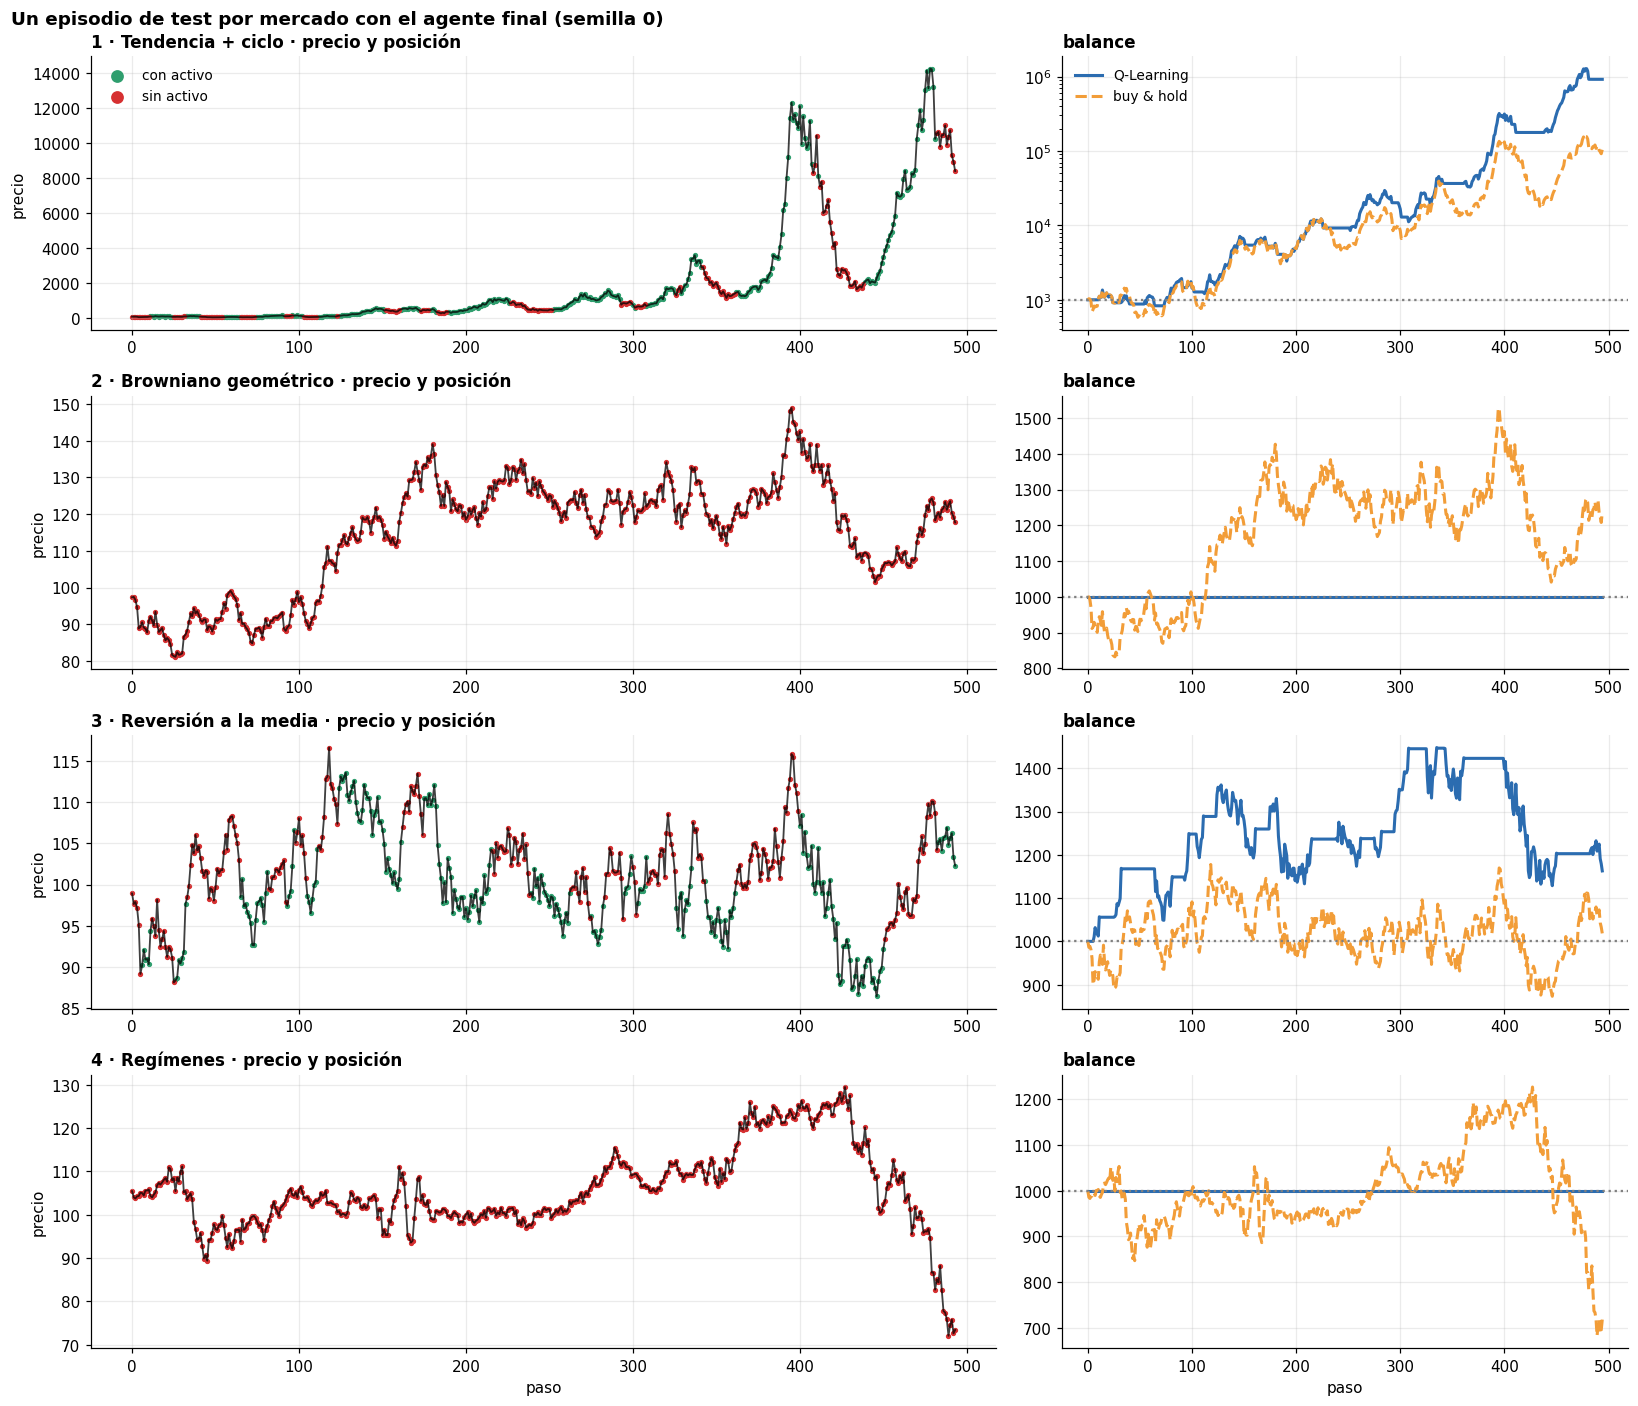

In [13]:
from src.agents import QLearningAgent as _Q
fig, axes = plt.subplots(4, 2, figsize=(15, 13), gridspec_kw={"width_ratios": [1.6, 1]})
for i, m in enumerate(MARKETS):
    cfg = cfg4[m]
    ag = _Q(edges=quantile_edges(m, cfg["n_bins"]), alpha=cfg["alpha"], gamma=cfg["gamma"])
    ag.Q = qs_f[df_f[(df_f.mercado == m) & (df_f.seed == 0)].id.iloc[0]].copy()
    prices = make_prices(m, 500, 100_000)                       # primera serie de test
    _, bal, _, pos = run_episode(SimpleTradingEnv(prices), ag, learn=False, greedy=True)
    vp = prices[5:-1]
    ax = axes[i, 0]
    ax.plot(vp, color="black", lw=1.2, alpha=0.75)
    ax.scatter(np.where(pos == 1)[0], vp[pos == 1], s=6, color="#2F9E6E", label="con activo")
    ax.scatter(np.where(pos == 0)[0], vp[pos == 0], s=6, color="#D63031", label="sin activo")
    ax.set_title(f"{MARKET_LABELS[m]} · precio y posición", loc="left"); ax.set_ylabel("precio")
    ax = axes[i, 1]
    ax.plot(bal, color=AGENT_COLORS["qlearning"], lw=2, label="Q-Learning")
    ax.plot(1000 * 0.999 / prices[5] * prices[5:], color=AGENT_COLORS["buy_hold"], ls="--", lw=2, label="buy & hold")
    ax.axhline(1000, color="gray", ls=":")
    ax.set_title("balance", loc="left"); ax.set_yscale("log" if m == "tendencia_ciclo" else "linear")
axes[0, 0].legend(loc="upper left", markerscale=3); axes[0, 1].legend(loc="upper left")
axes[-1, 0].set_xlabel("paso"); axes[-1, 1].set_xlabel("paso")
fig.suptitle("Un episodio de test por mercado con el agente final (semilla 0)", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "01_episodios_test"); plt.show()

**Lectura, mercado a mercado** (comparando con las hipótesis del 00 §2):

| Mercado | Qué ha aprendido | ¿Esperado? |
|---|---|---|
| **1 · Tendencia + ciclo** | Entra cuando la tendencia está en los bins altos (7–10) y sale en los bajos (1–3). En los intermedios (4–6) no cambia de posición: es una **banda de indiferencia** que ahorra comisiones. Las 5 semillas coinciden en casi todo | ✅ Seguimiento de tendencia. Bate a buy & hold por ≈ 15 veces (x502 frente a x34) |
| **2 · Browniano** | No entra nunca | ✅ No hay nada que aprender: operar solo paga comisiones. Su 0 % "bate" a buy & hold (−3,5 %), pero eso no es habilidad, es prudencia |
| **3 · Reversión a la media** | Compra solo tras la **caída más fuerte** (bin 1) y vende solo tras la **subida más fuerte** (bin 10). Mantiene la posición en todo lo demás | ✅ Reversión de libro: compra barato y vende caro, solo en los extremos. Opera la mitad que en el 00 (29 frente a 64 operaciones) y gana el doble (+27 % frente a +13,6 %) |
| **4 · Regímenes** | No entra nunca | ⚠️ Se esperaba seguimiento de tendencia. ¿Por qué no lo hace? Lo analiza el §9 |

La tabla se basa en las 5 semillas. El episodio de ejemplo es una **ilustración cualitativa** con una sola serie de
test: en el mercado 1 se ve al agente dentro en los tramos de subida y fuera en las caídas fuertes, y en el 3 comprando
en los valles y vendiendo en los picos.

## 9. El reto del mercado 4

En regímenes, lo esperable era **seguir la tendencia**: entrar cuando sube y salir cuando baja. ¿Por qué el agente
no lo hace? Hay dos posibilidades:

1. **No sabe aprenderlo** (un problema del algoritmo o de los hiperparámetros).
2. **Con este estado no compensa** (un problema de la información disponible): la tendencia de 6 precios reacciona
   tarde y las comisiones se comen la ventaja.

Para distinguirlas se prueban **todas las reglas sencillas de seguimiento de tendencia** que caben en nuestro estado:
"entrar cuando el bin ≥ *e* y salir cuando el bin ≤ *x*". Se evalúan en las mismas series de validación. Si ni la
mejor regla bate a "no operar", el agente ha aprendido lo correcto: **con esta observación, quedarse fuera es lo óptimo**.

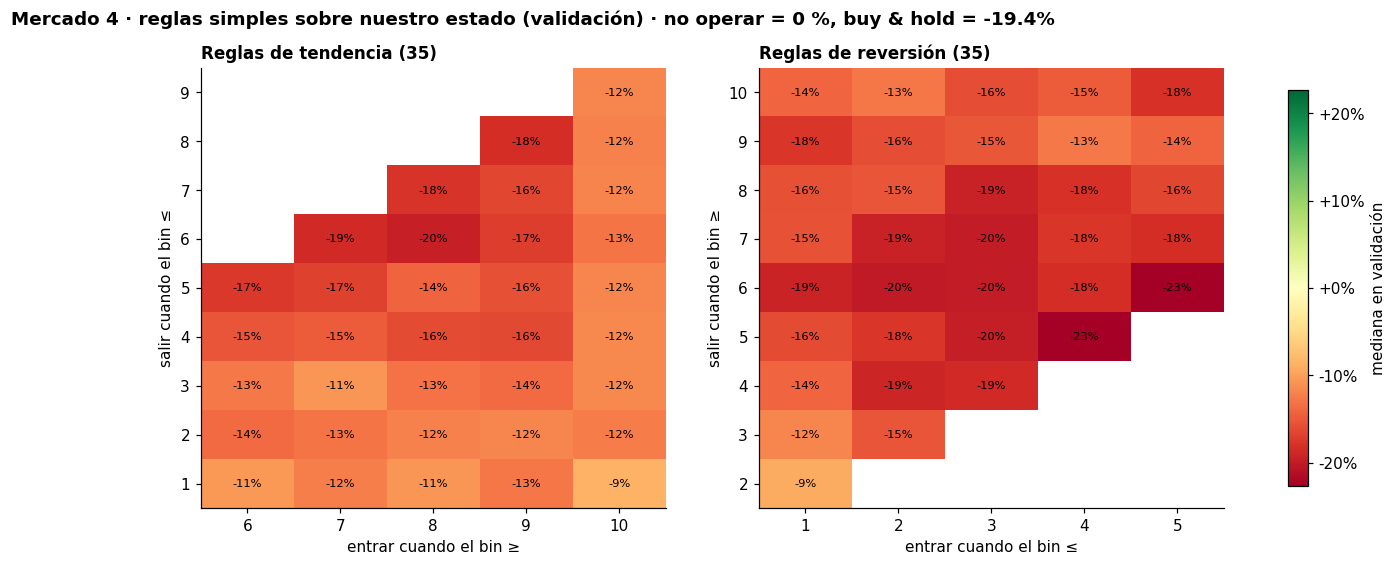

,entrar (bin),salir (bin),mejor mediana,ops,peor de la familia
tipo,,,,,
reversión,1,2,-9.2%,41,-22.7%
tendencia,10,1,-8.6%,21,-19.6%


In [14]:
class Regla:
    """Política fija según el bin de tendencia (diagnóstico; no aprende).
    tendencia: entrar si bin >= e, salir si bin <= x  ·  reversión: entrar si bin <= e, salir si bin >= x"""
    def __init__(self, edges, tipo, e, x):
        self.edges, self.tipo, self.e, self.x = edges, tipo, e, x
    def act(self, s, greedy=False):
        b, pos = divmod(s, 2)
        if self.tipo == "tendencia":
            return (2 if b >= self.e else 1) if pos == 0 else (0 if b <= self.x else 1)
        return (2 if b <= self.e else 1) if pos == 0 else (0 if b >= self.x else 1)
    def update(self, *a): pass
    def end_episode(self): pass

m4 = "regimenes"
edges4 = quantile_edges(m4, N_BINS)
n_reglas = 20 if QUICK else N_VAL
filas = []
for e in range(N_BINS // 2, N_BINS):          # tendencia: entrar en bins altos
    for x in range(0, e):
        r = evaluate(Regla(edges4, "tendencia", e, x), m4, n_test=n_reglas, split="val")
        filas.append({"tipo": "tendencia", "e": e + 1, "x": x + 1, "mediana": r.retorno.median(), "ops": r.n_trades.mean()})
for e in range(0, N_BINS // 2):               # reversión: entrar en bins bajos
    for x in range(e + 1, N_BINS):
        r = evaluate(Regla(edges4, "reversion", e, x), m4, n_test=n_reglas, split="val")
        filas.append({"tipo": "reversión", "e": e + 1, "x": x + 1, "mediana": r.retorno.median(), "ops": r.n_trades.mean()})
reglas = pd.DataFrame(filas)
bh4_val = evaluate(BuyHoldAgent(), m4, n_test=n_reglas, split="val").retorno.median()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
lim = np.nanmax(np.abs(reglas.mediana))
for ax, tipo, xl, yl in [(axes[0], "tendencia", "entrar cuando el bin ≥", "salir cuando el bin ≤"),
                         (axes[1], "reversión", "entrar cuando el bin ≤", "salir cuando el bin ≥")]:
    mat = reglas[reglas.tipo == tipo].pivot(index="x", columns="e", values="mediana")
    im = ax.imshow(mat.values, cmap="RdYlGn", vmin=-lim, vmax=lim, origin="lower", aspect="auto")
    for (i, j), v in np.ndenumerate(mat.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.0%}", ha="center", va="center", fontsize=7.5)
    ax.set_xticks(range(mat.shape[1]), mat.columns); ax.set_yticks(range(mat.shape[0]), mat.index)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(False)
    ax.set_title(f"Reglas de {tipo} ({(reglas.tipo == tipo).sum()})", loc="left")
plt.colorbar(im, ax=axes, format=plt.FuncFormatter(lambda v, _: f"{v:+.0%}"), label="mediana en validación", shrink=0.9)
fig.suptitle(f"Mercado 4 · reglas simples sobre nuestro estado (validación) · no operar = 0 %, buy & hold = {bh4_val:+.1%}",
             x=0.01, ha="left", weight="bold")
savefig(fig, "01_reglas_mercado4"); plt.show()

mejores = reglas.loc[reglas.groupby("tipo").mediana.idxmax()].set_index("tipo")
mejores["peor de la familia"] = reglas.groupby("tipo").mediana.min()
display(mejores.rename(columns={"e": "entrar (bin)", "x": "salir (bin)", "mediana": "mejor mediana"})
        .style.format({"mejor mediana": "{:+.1%}", "peor de la familia": "{:+.1%}", "ops": "{:.0f}"})
        .set_caption(f"Mejor regla de cada familia en validación (buy & hold en validación: {bh4_val:+.1%})"))


**Veredicto: con este estado no hay ninguna ventaja simple que explotar, y el agente lo ha aprendido.** Se han probado
**70 reglas** sobre el bin de tendencia: 35 de seguimiento de tendencia y 35 de reversión. **Todas pierden dinero** en
validación: la mejor de tendencia da −8,6 % y la mejor de reversión −9,2 %. Las mejores baten a buy & hold en las
mismas series (−19,4 %), pero **ninguna se acerca a no operar (0 %)**. Es una prueba fuerte, aunque no una demostración,
de que con esta observación quedarse fuera es lo mejor que se puede hacer. Q-Learning ha llegado a esa misma
conclusión por su cuenta: el límite está en la información del estado, no en el algoritmo.

**Por qué el seguimiento de tendencia no funciona aquí** (interpretación coherente con los datos):

- **Llega tarde.** La tendencia compara el precio con la media de los 6 últimos, así que un cambio de régimen se
  detecta con varios pasos de retraso, y las caídas del régimen bajista son bruscas.
- **Señales falsas.** Según el generador del taller (`src/markets.py`), el régimen bajista tiene una volatilidad 2,5
  veces mayor (σ = 2,5 % frente a 1 % por paso). Eso provoca entradas y salidas en falso, cada una con su comisión.
- **No sabe en qué régimen está.** La tendencia de 6 pasos no distingue un rebote dentro de un régimen bajista de un
  régimen alcista nuevo. El estado no es markoviano para este mercado, como avisó el profesor ("depende de cómo
  definas el estado", ~01:34).

**Qué haría falta (para el 03):** información que identifique el régimen, como una tendencia a más plazo (20–50
pasos) o una medida de volatilidad reciente. Eso cambia el estado, así que es una prueba "más allá de los mínimos".

## 10. Conclusiones

### Resultado final (test, 200 series, mediana de 5 semillas)

| Mercado | Aleatorio | Buy & hold | **Q-Learning** | Ops/episodio | Converge en (§6) | Estrategia |
|---|---|---|---|---|---|---|
| 1 · Tendencia + ciclo | x4,3 | x33,6 | **x502** (x472–x605) | 48 | 107 ep. | Sigue la tendencia, con banda de indiferencia |
| 2 · Browniano | −19,4 % | −3,5 % | **0 %** | 0 | — | No opera (correcto: no hay señal) |
| 3 · Reversión a la media | −17,2 % | −0,3 % | **+27,0 %** (+22,5 – +27,0 %) | 29 | 262 ep. | Compra en el extremo bajista y vende en el alcista |
| 4 · Regímenes | −22,0 % | −12,5 % | **0 %** | 0 | — | No opera: ninguna regla simple bate a no operar (§9) |

### Lo que hemos aprendido

| # | Hallazgo | Evidencia |
|---|---|---|
| 1 | **α = 0,001 en los cuatro mercados.** Entre 0,0005 y 0,01 los resultados son casi iguales (una meseta estable); con 0,03 empeora y con 0,1 se hunde (mercado 1: x14; reversión: no opera). Confirma D-2.2 | §3 |
| 2 | **γ depende del mercado.** En el 1, el mejor es **γ = 0** (miope): con un 10 % de ruido por paso (00 §2) el futuro es impredecible y basta con la señal inmediata. En el 3, **γ = 0,5**: con γ = 0 no opera, porque el rebote tarda varios pasos, y con γ = 0,9 rinde menos (+22 % frente a +34 % en validación) | §4 |
| 3 | **La exploración apenas importa salvo en el mercado 1**, donde decaer más rápido con un mínimo de 0,05 mejora (x817 frente a x596 en validación). En los mercados que operan (1 y 3), decaer demasiado despacio (0,995) empeora, porque con 500 episodios todavía explora un 8 % | §5 |
| 4 | **500 episodios bastan con este calendario de ε.** Las curvas se estabilizan en 107 (mercado 1) y 262 episodios (mercado 3), y 1 000 o 2 000 episodios no mejoran la validación. Los episodios y el calendario de ε están acoplados (limitación del §6) | §6 |
| 5 | **Ajustar por mercado compensa**: frente a la configuración común de partida (α 0,001, γ 0,9, ε 0,99/0,01), mejora la validación de x527 a x817 en el mercado 1 y de +22 % a +34 % en el 3 | §3–§5 |
| 6 | **La validación es optimista**: x817 frente a x502 en el mercado 1 (−39 %) y +34 % frente a +27 % en el 3. Una parte es sesgo de selección (nos quedamos con el máximo) y otra que son series distintas, muy ruidosas en el mercado 1. Por eso el test se usa una sola vez | §7 |
| 7 | **Menos riesgo además de más retorno**: en el mercado 1 el Sharpe sube de 0,115 a 0,193 y la caída máxima baja del 89 % al 64 %; en el 3, de 0,010 a 0,041 y del 26 % al 20 % | §7 |
| 8 | **La estrategia aprendida es la esperada en los mercados 1, 2 y 3.** En el 4, ninguna de las 70 reglas simples sobre el estado (tendencia o reversión) bate a no operar: el límite está en el estado | §8, §9 |

### Hiperparámetros finales por mercado

| Mercado | α | γ | ε (decaimiento / mínimo) | Episodios |
|---|---|---|---|---|
| 1 · Tendencia + ciclo | 0,001 | 0 | 0,98 / 0,05 | 500 |
| 2 · Browniano | 0,001 | 0,9 | 0,99 / 0,01 | 500 |
| 3 · Reversión a la media | 0,001 | 0,5 | 0,99 / 0,01 | 500 |
| 4 · Regímenes | 0,001 | 0,9 | 0,99 / 0,01 | 500 |

En los mercados 2 y 4 se mantienen los valores de partida, porque el agente no opera con ninguna combinación (regla
de parsimonia del §2).

### Para el 02 (SARSA) y el 04

- **Mismo protocolo** (validación, 3 semillas, etapas y parsimonia) con `run_grid(..., "02_grid_...")`. Así la
  comparación en el 04 es justa.
- **Pregunta del profesor** ("¿qué algoritmo converge antes?"): aquí Q-Learning converge en 107 episodios en el
  mercado 1 y en 262 en el 3 (mediana de 3 semillas con 2 000 episodios). La teoría (slides3, cliff walking) predice que SARSA será **más conservador** mientras
  ε > 0. Hay que comprobar si eso le hace operar menos o converger más despacio.
- **Para el 03:** el mercado 4 necesita un estado que identifique el régimen (§9).